# code_075 · Additive spline and shape-constrained models

**Book:** section 15.4. A self-contained transparent response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_15_GUIDE.md), [run evidence](../CHAPTER_15_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_075).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1575;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1575


<a id="additive"></a>
## A nonlinear additive predictor with a declared load constraint

Generate load l in[0,1], temperature t in[-1,1], failure chance sigmoid(-2+3*l²+1.5*t²). Train350, development150, independent calibration300, final400. The monotone load effect is justified only within this generated mechanism, not arbitrary structures. Four clipped ramps form a continuous piecewise-linear load spline between fixed knots0,.25,.5,.75,1 have nonnegative coefficients, enforcing a nondecreasing piecewise-linear load logit. Temperature uses a training-fitted five-knot cubic B-spline with free coefficients. This is a scoped additive logistic fit, not a general GAM library. Choose quadratic penalty .001,.01,.1 on development log loss; no final refit. Compare a fixed linear logistic baseline. A separate locked slice of200 observations at temperature0 supplies the identical load/response/residual axes for both fits.


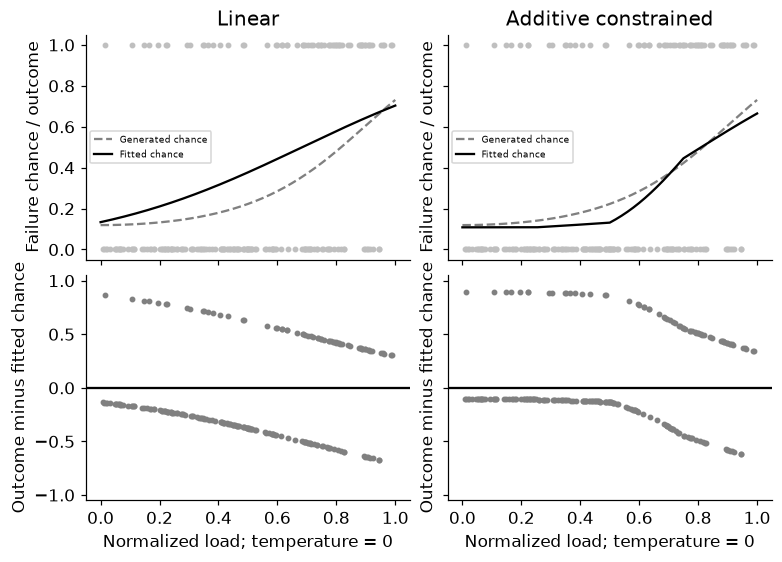

In [2]:
from scipy.special import expit
from scipy.optimize import minimize,check_grad
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import log_loss,brier_score_loss
def generate(n,temperature=None):
 a=np.column_stack([rng.uniform(0,1,n),rng.uniform(-1,1,n) if temperature is None else np.full(n,temperature)]);p=expit(-2+3*a[:,0]**2+1.5*a[:,1]**2);return a,rng.binomial(1,p),p
X,y,_=generate(350);Xd,yd,_=generate(150);Xc,yc,_=generate(300);Xt,yt,truth=generate(400);spl=SplineTransformer(n_knots=5,degree=3,include_bias=False,extrapolation='constant').fit(X[:,1:]);knots=np.linspace(0,1,5)
def basis(a):return np.column_stack([np.ones(len(a)),np.clip((a[:,0,None]-knots[:-1])/np.diff(knots),0,1),spl.transform(a[:,1:])])
B=basis(X);Bd=basis(Xd);bounds=[(None,None)]+[(0,None)]*4+[(None,None)]*(B.shape[1]-5)
def fit(lam):
 def loss(b):return float(np.mean(np.logaddexp(0,B@b)-y*(B@b))+.5*lam*np.sum(b[1:]**2))
 def grad(b):return B.T@(expit(B@b)-y)/len(y)+lam*np.r_[0,b[1:]]
 if lam==.001:assert check_grad(loss,grad,np.ones(B.shape[1])*.1)<1e-5
 out=minimize(loss,np.zeros(B.shape[1]),jac=grad,bounds=bounds,method='L-BFGS-B',options={'ftol':1e-12,'gtol':1e-8,'maxiter':2000});assert out.success,out.message;return out.x
penalties=[.001,.01,.1];coefs=[fit(l) for l in penalties];scores=[log_loss(yd,expit(Bd@b)) for b in coefs];j=int(np.argmin(scores));coef=coefs[j];linear=LogisticRegression(C=1,max_iter=1000).fit(X,y)
def additive(a):return expit(basis(a)@coef)
grid=np.column_stack([np.linspace(0,1,201),np.zeros(201)]);assert np.min(np.diff(additive(grid)))>=-1e-12 and np.all(coef[1:5]>=0)
p=additive(Xt);RESULTS['fit']={'selected_penalty':penalties[j],'development_log_losses':scores,'load_logit_increments':coef[1:5].tolist(),'linear_final_log_loss':float(log_loss(yt,linear.predict_proba(Xt)[:,1])),'additive_final_log_loss':float(log_loss(yt,p)),'linear_final_brier':float(brier_score_loss(yt,linear.predict_proba(Xt)[:,1])),'additive_final_brier':float(brier_score_loss(yt,p)),'monotone_within_unit_load_support':True};RESULTS['roles']={'train':350,'development':150,'calibration':300,'final':400,'locked_zero_temperature_slice':200}
Xs,ys,ps=generate(200,temperature=0);fig,axes=plt.subplots(2,2,figsize=(7,5),sharex=True,sharey='row')
for col,(name,predict) in enumerate([('Linear',lambda a:linear.predict_proba(a)[:,1]),('Additive constrained',additive)]):
 pred=predict(Xs);axes[0,col].scatter(Xs[:,0],ys,s=8,color='.75');axes[0,col].plot(grid[:,0],expit(-2+3*grid[:,0]**2),'--',color='.5',label='Generated chance');axes[0,col].plot(grid[:,0],predict(grid),color='black',label='Fitted chance');axes[0,col].set(title=name,ylabel='Failure chance / outcome',ylim=(-.05,1.05));axes[0,col].legend(fontsize=6)
 axes[1,col].scatter(Xs[:,0],ys-pred,s=8,color='.5');axes[1,col].axhline(0,color='black');axes[1,col].set(xlabel='Normalized load; temperature = 0',ylabel='Outcome minus fitted chance',ylim=(-1.05,1.05))
RESULTS['locked_slice']={'linear_log_loss':float(log_loss(ys,linear.predict_proba(Xs)[:,1])),'additive_log_loss':float(log_loss(ys,additive(Xs))),'rows':200};plt.show()


<a id="calibration"></a>
## Calibrate on a separate role and retain a possibly worse result

Isotonic regression fits a nondecreasing mapping from raw additive probabilities to outcomes using only the300 calibration records. Set increasing=True and out_of_bounds=clip explicitly. Evaluate raw and calibrated predictions on unchanged final records. Clip probabilities to[1e-6,1-1e-6] only for the reported log-loss calculation, so an extreme empirical calibration endpoint does not yield an infinite finite-sample score. This numerical reporting floor is not evidence that such probabilities are calibrated. Monotone composition preserves load ordering but cannot manufacture causal meaning or reliable extrapolation. The ramp load basis saturates outside[0,1]; the temperature spline uses constant extension. Neither extends the physical validity of the mechanism.


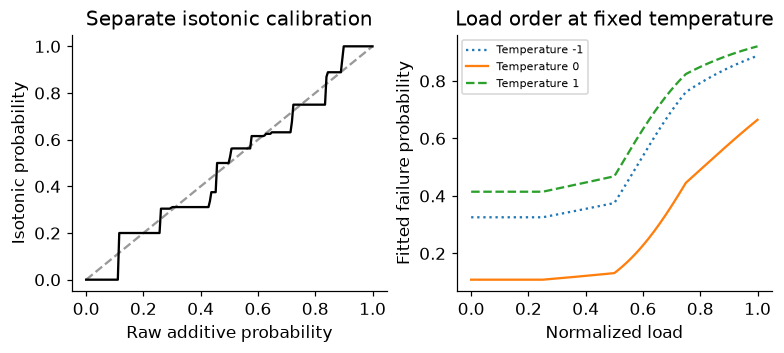

In [3]:
iso=IsotonicRegression(increasing=True,out_of_bounds='clip').fit(additive(Xc),yc);cal=iso.predict(p);assert np.all(np.diff(iso.predict(np.linspace(0,1,200)))>=-1e-12)
RESULTS['calibration']={'calibration_rows':300,'final_rows':400,'raw_brier':float(brier_score_loss(yt,p)),'isotonic_brier':float(brier_score_loss(yt,cal)),'raw_log_loss_clipped_1e_6':float(log_loss(yt,np.clip(p,1e-6,1-1e-6))),'isotonic_log_loss_clipped_1e_6':float(log_loss(yt,np.clip(cal,1e-6,1-1e-6))),'final_endpoint_probabilities':int(np.sum((cal==0)|(cal==1)))}
fig,axes=plt.subplots(1,2,figsize=(7,3.1));q=np.linspace(0,1,200);axes[0].plot(q,q,'--',color='.6');axes[0].plot(q,iso.predict(q),color='black');axes[0].set(xlabel='Raw additive probability',ylabel='Isotonic probability',title='Separate isotonic calibration')
for temp,style in [(-1,':'),(0,'-'),(1,'--')]:
 a=grid.copy();a[:,1]=temp;axes[1].plot(a[:,0],additive(a),style,label=f'Temperature {temp}')
axes[1].set(xlabel='Normalized load',ylabel='Fitted failure probability',title='Load order at fixed temperature');axes[1].legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_075','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['linear versus additive response on a fixed cohort', 'training-fitted spline basis and penalty selection', 'nonnegative monotone load increments', 'independent isotonic calibration and limits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["linear versus additive response on a fixed cohort", "training-fitted spline basis and penalty selection", "nonnegative monotone load increments", "independent isotonic calibration and limits"], "elapsed_seconds": 0.345, "example_id": "code_075", "hardware": "Darwin arm64 CPU", "results": {"calibration": {"calibration_rows": 300, "final_endpoint_probabilities": 22, "final_rows": 400, "isotonic_brier": 0.19349627549888304, "isotonic_log_loss_clipped_1e_6": 0.6522185413388685, "raw_brier": 0.19351061858965393, "raw_log_loss_clipped_1e_6": 0.5756794966156943}, "fit": {"additive_final_brier": 0.19351061858965393, "additive_final_log_loss": 0.5756794966156943, "development_log_losses": [0.5542417938817957, 0.5553526989254605, 0.5997306994635], "linear_final_brier": 0.19936902495199774, "linear_final_log_loss": 0.5860649542591362, "load_logit_increments": [0.0, 0.21782717292982626, 1.6714651381944252, 0.9026336249002458], "monotone_within_uni